In [1]:
#读取数据
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 让图表里的中文正常显示（Mac 自带字体）
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

# 传感器数据：用空格分隔，没有表头
X = pd.read_csv("raw/secom.data", sep=" ", header=None)
X.columns = [f"f{i}" for i in range(X.shape[1])]   # 给特征命名为 f0, f1, ...

# 标签和时间戳
y_df = pd.read_csv("raw/secom_labels.data", sep=" ", header=None,
                   names=["label", "timestamp"])
y_df["timestamp"] = pd.to_datetime(y_df["timestamp"], dayfirst=True)

print("特征数据形状:", X.shape)
print("标签数据形状:", y_df.shape)
y_df.head()

特征数据形状: (1567, 590)
标签数据形状: (1567, 2)


,label,timestamp
0,-1,2008-07-19 11:55:00
1,-1,2008-07-19 12:32:00
2,1,2008-07-19 13:17:00
3,-1,2008-07-19 14:43:00
4,-1,2008-07-19 15:22:00


In [2]:
#标签分布
counts = y_df["label"].value_counts()
print(counts)
print("\n不良率: {:.2%}".format((y_df["label"] == 1).mean()))

label
-1    1463
 1     104
Name: count, dtype: int64

不良率: 6.64%


In [3]:
#时间范围与每周不良率
print("最早:", y_df["timestamp"].min())
print("最晚:", y_df["timestamp"].max())

# 按周统计生产数量和不良率
weekly = y_df.set_index("timestamp").resample("W")["label"].agg(
    total="count", fails=lambda s: (s == 1).sum())
weekly["fail_rate"] = weekly["fails"] / weekly["total"]
weekly

最早: 2008-07-19 11:55:00
最晚: 2008-10-17 06:07:00


,total,fails,fail_rate
timestamp,,,
2008-07-20,13,3,0.230769
2008-07-27,21,2,0.095238
2008-08-03,48,10,0.208333
2008-08-10,108,14,0.129630
2008-08-17,51,7,0.137255
2008-08-24,208,22,0.105769
2008-08-31,169,7,0.041420
2008-09-07,133,2,0.015038
2008-09-14,95,4,0.042105


完全没有缺失的特征数: 52
缺失率 > 50% 的特征数: 28
缺失率 > 80% 的特征数: 8


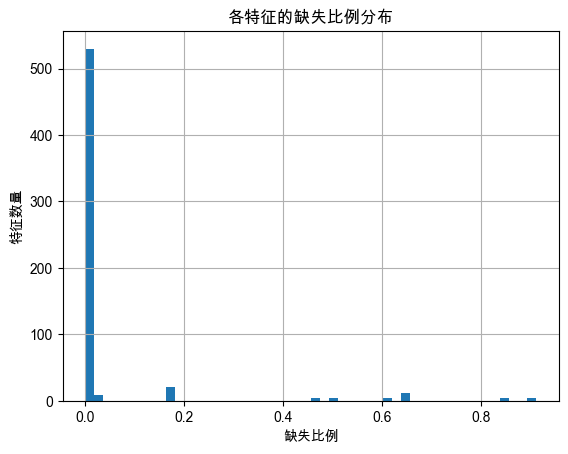

In [4]:
#缺失值概况
missing_ratio = X.isna().mean().sort_values(ascending=False)

print("完全没有缺失的特征数:", (missing_ratio == 0).sum())
print("缺失率 > 50% 的特征数:", (missing_ratio > 0.5).sum())
print("缺失率 > 80% 的特征数:", (missing_ratio > 0.8).sum())

missing_ratio.hist(bins=50)
plt.xlabel("缺失比例")
plt.ylabel("特征数量")
plt.title("各特征的缺失比例分布")
plt.show()

In [5]:
#取值不变的特征
n_unique = X.nunique(dropna=True)
print("只有一个取值（常数）的特征数:", (n_unique <= 1).sum())

只有一个取值（常数）的特征数: 116


            total  fails  fail_rate
timestamp                          
2008-07-01     63     14   0.222222
2008-08-01    555     51   0.091892
2008-09-01    590     17   0.028814
2008-10-01    359     22   0.061281


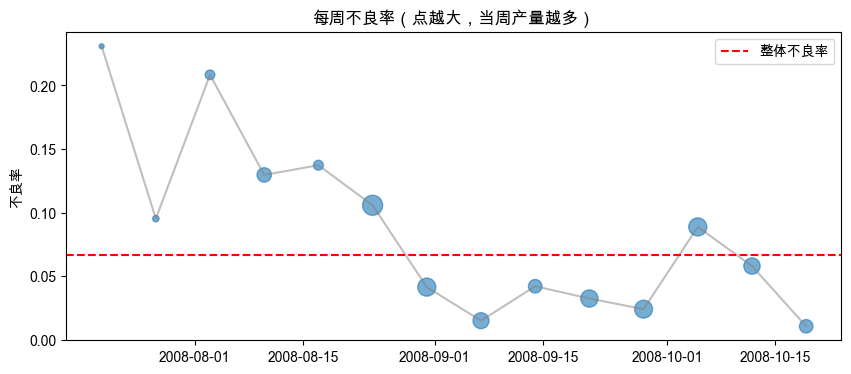

In [6]:
#按月看不良率
monthly = y_df.set_index("timestamp").resample("MS")["label"].agg(
    total="count", fails=lambda s: (s == 1).sum())
monthly["fail_rate"] = monthly["fails"] / monthly["total"]
print(monthly)

# 每周不良率趋势图（点的大小代表当周产量）
plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly["fail_rate"], color="gray", alpha=0.5)
plt.scatter(weekly.index, weekly["fail_rate"], s=weekly["total"], alpha=0.6)
plt.axhline((y_df["label"] == 1).mean(), color="red", linestyle="--", label="整体不良率")
plt.ylabel("不良率")
plt.title("每周不良率（点越大，当周产量越多）")
plt.legend()
plt.show()

In [7]:
#检查“确实本身”是否和不良有关
y = (y_df["label"] == 1).astype(int)   # 不良 = 1，合格 = 0
high_missing = missing_ratio[missing_ratio > 0.5].index

rows = []
for col in high_missing:
    is_missing = X[col].isna()
    rows.append({
        "feature": col,
        "missing_ratio": round(is_missing.mean(), 3),
        "fail_rate_when_missing": round(y[is_missing].mean(), 3),
        "fail_rate_when_present": round(y[~is_missing].mean(), 3),
    })

missing_check = pd.DataFrame(rows).sort_values("missing_ratio", ascending=False)
missing_check

,feature,missing_ratio,fail_rate_when_missing,fail_rate_when_present
0,f157,0.912,0.067,0.058
1,f292,0.912,0.067,0.058
2,f293,0.912,0.067,0.058
3,f158,0.912,0.067,0.058
4,f492,0.856,0.069,0.049
5,f358,0.856,0.069,0.049
6,f85,0.856,0.069,0.049
7,f220,0.856,0.069,0.049
19,f517,0.650,0.073,0.055
18,f384,0.650,0.073,0.055


In [8]:
#删除常数特征和高缺失特征后还剩多少
const_cols = n_unique[n_unique <= 1].index
drop_cols = set(const_cols) | set(high_missing)

X_reduced = X.drop(columns=list(drop_cols))
print("常数特征:", len(const_cols))
print("高缺失特征:", len(high_missing))
print("两者重叠:", len(set(const_cols) & set(high_missing)))
print("删除后剩余特征数:", X_reduced.shape[1])

常数特征: 116
高缺失特征: 28
两者重叠: 0
删除后剩余特征数: 446


In [9]:
#这几个特征是否在同一批样本上缺失？缺失和时间有没有关系？
y = (y_df["label"] == 1).astype(int)

groups = {
    "组A (f72, f73, f345, f346)": ["f72", "f73", "f345", "f346"],
    "组B (f579, f580, f581)": ["f579", "f580", "f581"],
}

for name, cols in groups.items():
    flag = X[cols[0]].isna()
    same = all((X[c].isna() == flag).all() for c in cols[1:])
    print(f"\n{name}：缺失位置完全相同？ {same}")

    tmp = pd.DataFrame({"timestamp": y_df["timestamp"], "缺失比例": flag, "不良率": y})
    print(tmp.set_index("timestamp").resample("MS")[["缺失比例", "不良率"]].mean().round(3))


组A (f72, f73, f345, f346)：缺失位置完全相同？ True
             缺失比例    不良率
timestamp               
2008-07-01  0.159  0.222
2008-08-01  0.323  0.092
2008-09-01  0.620  0.029
2008-10-01  0.666  0.061

组B (f579, f580, f581)：缺失位置完全相同？ True
             缺失比例    不良率
timestamp               
2008-07-01  0.238  0.222
2008-08-01  0.622  0.092
2008-09-01  0.686  0.029
2008-10-01  0.513  0.061


In [10]:
#统计检验，差异是否显著？
from scipy.stats import chi2_contingency

for name, cols in groups.items():
    flag = X[cols[0]].isna()
    table = pd.crosstab(flag, y)
    table.index = ["不缺失", "缺失"]
    table.columns = ["合格", "不良"]
    chi2, p, _, _ = chi2_contingency(table)
    print(f"\n{name}")
    print(table)
    print(f"卡方检验 p 值 = {p:.4f}")


组A (f72, f73, f345, f346)
      合格  不良
不缺失  705  68
缺失   758  36
卡方检验 p 值 = 0.0010

组B (f579, f580, f581)
      合格  不良
不缺失  573  45
缺失   890  59
卡方检验 p 值 = 0.4694


In [11]:
#按月分层比较（组A）
flag_A = X["f72"].isna()
tmp = pd.DataFrame({
    "month": y_df["timestamp"].dt.to_period("M"),
    "缺失": flag_A.map({True: "缺失", False: "不缺失"}),
    "不良": y,
})

# 每个月内：缺失 vs 不缺失 的样本数和不良率
summary = tmp.groupby(["month", "缺失"])["不良"].agg(样本数="count", 不良数="sum", 不良率="mean")
summary["不良率"] = summary["不良率"].round(3)
summary

样本数  不良数    不良率
month   缺失                  
2008-07 不缺失   53   13  0.245
        缺失    10    1  0.100
2008-08 不缺失  376   40  0.106
        缺失   179   11  0.061
2008-09 不缺失  224    8  0.036
        缺失   366    9  0.025
2008-10 不缺失  120    7  0.058
        缺失   239   15  0.063